In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
FILE = '/Data/skd/scratch/innag3580/comp/smoc55_picontrol/smoc55_picontrol.nc'

ds = xr.open_dataset(FILE)
smoc = ds['smoc55_index']

print(f'Length : {len(smoc)} timesteps')
print(f'Mean   : {float(smoc.mean()):.4f} Sv')
print(f'Std    : {float(smoc.std()):.4f} Sv')
print(f'Min    : {float(smoc.min()):.4f} Sv')
print(f'Max    : {float(smoc.max()):.4f} Sv')

Length : 14400 timesteps
Mean   : 21.6599 Sv
Std    : 2.2971 Sv
Min    : 11.5770 Sv
Max    : 36.7220 Sv


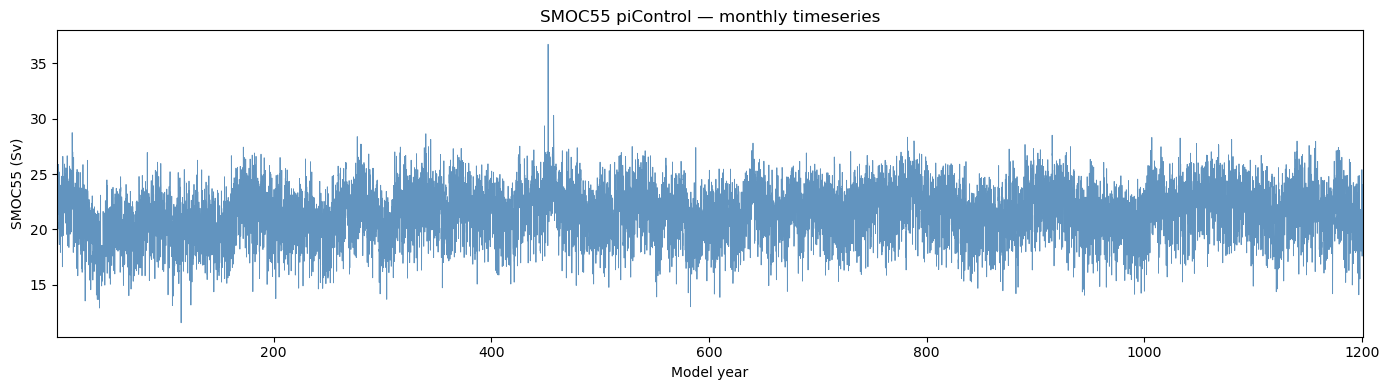

In [3]:
# Data is monthly (14400 timesteps = 1200 years x 12 months).
# Build a fractional model-year axis directly from the cftime coordinates.
years = np.array([t.year + (t.month - 1) / 12 for t in smoc.time.values])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(years, smoc.values, lw=0.6, color='steelblue', alpha=0.85)
ax.set_xlabel('Model year')
ax.set_ylabel('SMOC55 (Sv)')
ax.set_title('SMOC55 piControl — monthly timeseries')
ax.set_xlim(years[0], years[-1])
plt.tight_layout()
plt.show()

## Changepoint detection

In [4]:
# Sliding-window changepoint detection — same algorithm as change_point_analysis.py.
# Parameters: threshold=2-sigma (Below only), gap=5 years (paper figures value).
# Two configs: P1_len=40/P2_len=20 and P1_len=20/P2_len=20.

THRESHOLD = 2.0
GAP       = 5   # minimum years between events (from run_change_point.sh / plotting CSVs)

# Annual mean and integer year axis
annual      = smoc.resample(time='1Y').mean()
annual_vals = annual.values
annual_yrs  = np.array([t.year for t in annual.time.values])


def detect_below(annual_vals, annual_yrs, P1_len, P2_len, threshold=THRESHOLD, gap=GAP):
    """Return array of model years where a 'Below' event is detected."""
    events = []
    for j in range(P1_len, len(annual_vals) - P2_len):
        P1_avg = annual_vals[j - P1_len:j].mean()
        P1_std = annual_vals[j - P1_len:j].std()
        P2_avg = annual_vals[j:j + P2_len].mean()
        if P2_avg <= P1_avg - threshold * P1_std:
            if len(events) == 0 or annual_yrs[j] >= events[-1] + gap:
                events.append(annual_yrs[j])
    return np.array(events)


configs = [
    dict(P1_len=40, P2_len=20),
    dict(P1_len=20, P2_len=20),
]

events_per_config = {}
for cfg in configs:
    label  = f"P1={cfg['P1_len']}/P2={cfg['P2_len']}"
    events = detect_below(annual_vals, annual_yrs, cfg['P1_len'], cfg['P2_len'])
    events_per_config[label] = events
    print(f"{label}  →  {len(events)} Below events")

P1=40/P2=20  →  3 Below events
P1=20/P2=20  →  13 Below events


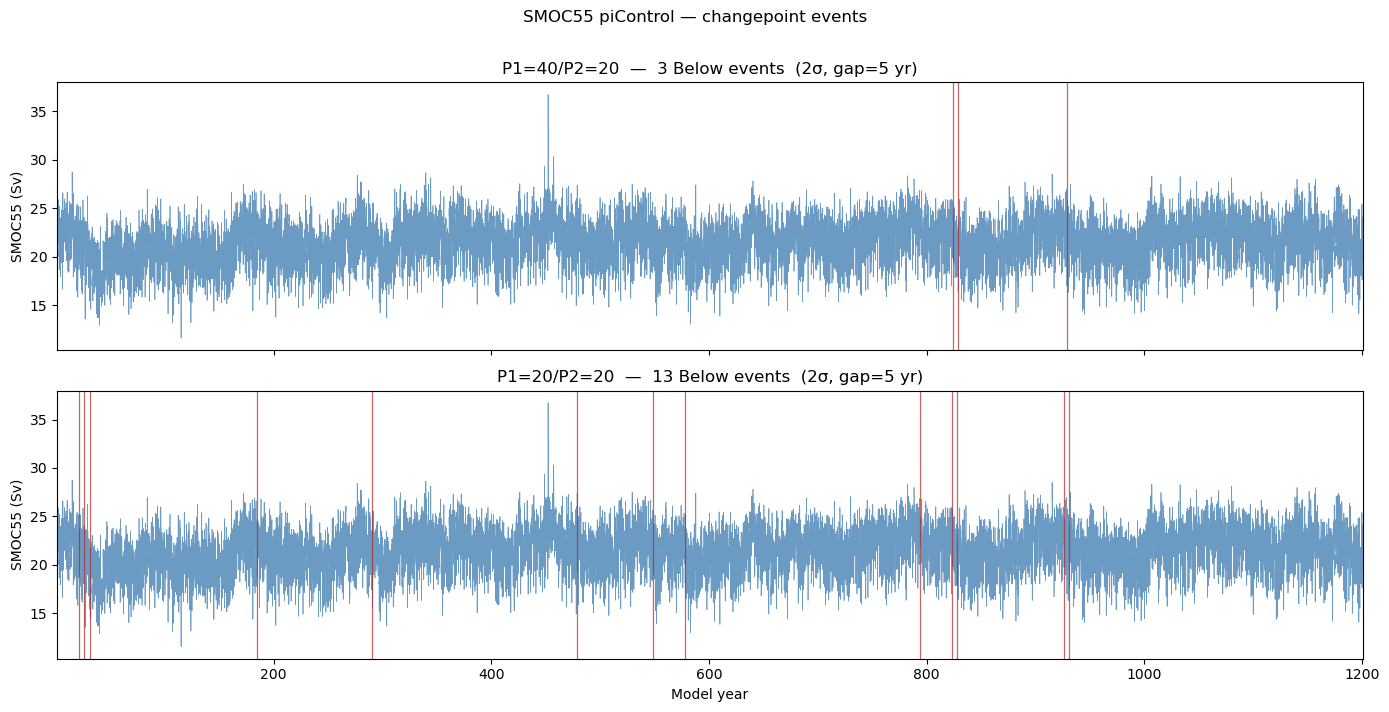

In [5]:
# Re-plot the monthly timeseries with detected Below events marked,
# one subplot per window-length config.

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, sharey=True)

for ax, (label, events) in zip(axes, events_per_config.items()):
    ax.plot(years, smoc.values, lw=0.5, color='steelblue', alpha=0.8, zorder=1)
    for yr in events:
        ax.axvline(yr, color='firebrick', lw=0.9, alpha=0.7, zorder=2)
    ax.set_ylabel('SMOC55 (Sv)')
    ax.set_title(f'{label}  —  {len(events)} Below events  (2σ, gap={GAP} yr)')
    ax.set_xlim(years[0], years[-1])

axes[-1].set_xlabel('Model year')
plt.suptitle('SMOC55 piControl — changepoint events', y=1.01)
plt.tight_layout()
plt.show()

## Composites

Load the three composite NetCDF files (BSF, thetao, so) produced by
`composites_picontrol_flipbook.py` and reproduce the 3×3 flip-book figure
inline for each window-length configuration.

In [6]:
# --- Shared setup for composite plotting ---
# Mirrors the grid-loading block in composites_picontrol_flipbook.py.

import gc
import pop_tools
import matplotlib.cm as cm
import cmocean.cm as cmo
import cartopy
import cartopy.crs as ccrs

OUTPUT_DIR = '/Data/skd/scratch/innag3580/comp/smoc55_picontrol/composites_flipbook'

# --- Figure style (same as composites_picontrol_flipbook.py) ---
two_col = 6.5   # 39 picas
plt.rcParams.update({
    'figure.figsize': (two_col, two_col * 0.6),
    'font.size': 11,
    'axes.titlesize': 11,
})
nature_coast = cartopy.feature.NaturalEarthFeature(
    'physical', 'land', '50m',
    linewidth=0.3, edgecolor='black', facecolor='whitesmoke')

# --- POP_gx1v7 grid metrics ---
print('Loading POP_gx1v7 grid metrics and masks ...', flush=True)
grid_name = 'POP_gx1v7'
grid  = pop_tools.get_grid(grid_name)
dz_m  = grid['dz'].values  * 1e-2   # cm -> m
DXU_m = grid['DXU'].values * 1e-2   # cm -> m
TLAT  = grid['TLAT'].values
TLONG = grid['TLONG'].values
ULAT  = grid['ULAT'].values
ULONG = grid['ULONG'].values
del grid; gc.collect()

# --- Region masks ---
region_defs_na = {
    'SubpolarAtlantic': [
        {'match': {'REGION_MASK': [6]},
         'bounds': {'TLAT': [10.0, 80.0], 'TLONG': [260.0, 360.0]}}
    ],
    'LabradorSea': [
        {'match': {'REGION_MASK': [8]}}
    ],
}
NA_mask = pop_tools.region_mask_3d(
    grid_name, region_defs=region_defs_na,
    mask_name='North Atlantic').sum('region')

region_defs_bsf = {
    'SubpolarAtlantic': [
        {'match': {'REGION_MASK': [6]},
         'bounds': {'TLAT': [10.0, 65.0], 'TLONG': [260.0, 360.0]}}
    ],
    'LabradorSea': [
        {'match': {'REGION_MASK': [8]},
         'bounds': {'TLAT': [10.0, 65.0], 'TLONG': [260.0, 360.0]}}
    ],
}
BSF_mask = pop_tools.region_mask_3d(
    grid_name, region_defs=region_defs_bsf,
    mask_name='North Atlantic BSF').sum('region')

print('Grid and masks ready.', flush=True)

Loading POP_gx1v7 grid metrics and masks ...


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Grid and masks ready.


In [ ]:
def plot_flipbook_inline(da_bsf, da_thetao, da_so, P1_len, P2_len, n_events):
    """
    3-row × 3-col orthographic flip-book figure (inline version).
    Identical to plot_flipbook() in composites_picontrol_flipbook.py
    except it calls plt.show() instead of savefig+close.

    BSF treatment matches Plot_decrease_aa.ipynb (cell 13):
      - ULAT/ULONG are cleaned of NaN/inf/masked values before plotting.
      - pcolormesh uses the masked BSF anomaly (anom_bsf_na).
      - contour uses the *unmasked* P1-mean baseline BSF.
    """
    shift       = P1_len
    years_ranges = [
        (shift - 15, shift -  5),
        (shift -  5, shift +  5),
        (shift +  5, shift + 15),
    ]
    col_names = [
        f'Pre-Shift ({shift - 15}\u2013{shift - 5} years)',
        f'Shift ({shift - 5}\u2013{shift + 5} years)',
        f'Post-Shift ({shift + 5}\u2013{shift + 15} years)',
    ]
    row_labels  = [
        r'$\Delta \psi_{b}$ [Sv]',
        r'$\Delta T$ [$^{\circ}$C]',
        r'$\Delta S$ [g kg$^{-1}$]',
    ]
    cmaps_list  = [cm.seismic, cmo.balance, cmo.tarn_r]
    vmins_list  = [-8, -0.8, -0.3]
    slice_z     = slice(5e2, 5.5e3)   # lev in cm (POP/CMIP6 native)

    # P1-mean baselines
    p1_slice        = slice(0, P1_len)
    baseline_bsf    = da_bsf   .isel(time=p1_slice).mean('time')
    baseline_thetao = da_thetao.isel(time=p1_slice).mean('time')
    baseline_so     = da_so    .isel(time=p1_slice).mean('time')

    # Anomalies
    anom_bsf    = da_bsf    - baseline_bsf
    anom_thetao = da_thetao - baseline_thetao
    anom_so     = da_so     - baseline_so

    # Depth-weighted vertical mean for T and S
    lev_dim   = 'lev' if 'lev' in da_thetao.dims else 'z_t'
    lev_coord = da_thetao[lev_dim].values
    dz_weights = xr.DataArray(dz_m, dims=[lev_dim], coords={lev_dim: lev_coord})

    def depth_mean(da):
        da_sel = da.sel({lev_dim: slice_z})
        w      = dz_weights.sel({lev_dim: slice_z}).fillna(0)
        return da_sel.weighted(w).mean(lev_dim)

    anom_thetao_z = depth_mean(anom_thetao)
    anom_so_z     = depth_mean(anom_so)

    # Climatological T/S fields for contour lines (masked to North Atlantic)
    clim_thetao = depth_mean(baseline_thetao).where(NA_mask == 1)
    clim_so     = depth_mean(baseline_so    ).where(NA_mask == 1)

    # BSF: pcolormesh uses masked anomaly; contour uses *unmasked* P1 baseline.
    # Matches Plot_decrease_aa.ipynb cell 13 — masking the BSF before contouring
    # produces spurious lines along the mask boundary.
    anom_bsf_na = anom_bsf.where(BSF_mask == 1)

    # Clean ULAT/ULONG of NaN/inf/masked values before passing to matplotlib
    # (same fix applied to ds_vvel_original in Plot_decrease_aa.ipynb cell 13)
    import numpy.ma as npma
    _fill = 0
    ULONG_c = np.where(np.isnan(ULONG) | np.isinf(ULONG) | npma.getmaskarray(ULONG), _fill, ULONG)
    ULAT_c  = np.where(np.isnan(ULAT)  | np.isinf(ULAT)  | npma.getmaskarray(ULAT),  _fill, ULAT)

    # Figure
    alphabet  = 'abcdefghi'
    label_idx = 0

    fig, axes = plt.subplots(
        nrows=3, ncols=3,
        subplot_kw={'projection': ccrs.Orthographic(
            central_latitude=35, central_longitude=-35)})

    fig.suptitle(
        f'piControl Below events  \u2014  P1={P1_len} / P2={P2_len}  '
        f'({n_events} events, 2\u03c3, gap=5 yr)',
        y=1.02)

    for col, col_name in enumerate(col_names):
        axes[0, col].set_title(col_name, pad=14)

    # Row 0 — BSF
    # pcolormesh: masked anomaly on cleaned U-grid coords
    # contour:    unmasked P1 baseline on cleaned U-grid coords
    for col, (t0, t1) in enumerate(years_ranges):
        ax = axes[0, col]
        da = anom_bsf_na.isel(time=slice(t0, t1)).mean('time')
        ax.pcolormesh(ULONG_c, ULAT_c, da.values,
                      transform=ccrs.PlateCarree(),
                      cmap=cmaps_list[0], vmin=vmins_list[0], vmax=-vmins_list[0])
        ax.contour(ULONG_c, ULAT_c, baseline_bsf.values,
                   linewidths=0.3, colors='k', transform=ccrs.PlateCarree())
        ax.set_extent([-90, -5, 35, 65], crs=ccrs.PlateCarree())
        ax.add_feature(nature_coast)
        ax.text(0.03, 0.95, f'({alphabet[label_idx]})', transform=ax.transAxes,
                fontweight='bold', va='top', ha='left', zorder=15)
        label_idx += 1
        for spine in ax.spines.values(): spine.set_linewidth(0.3)

    # Row 1 — thetao
    for col, (t0, t1) in enumerate(years_ranges):
        ax = axes[1, col]
        da = anom_thetao_z.isel(time=slice(t0, t1)).mean('time')
        ax.pcolormesh(TLONG, TLAT, da.values,
                      transform=ccrs.PlateCarree(),
                      cmap=cmaps_list[1], vmin=vmins_list[1], vmax=-vmins_list[1])
        ax.contour(TLONG, TLAT, clim_thetao.values,
                   linewidths=0.3, colors='k', transform=ccrs.PlateCarree())
        ax.set_extent([-90, -5, 35, 65], crs=ccrs.PlateCarree())
        ax.add_feature(nature_coast)
        ax.text(0.03, 0.95, f'({alphabet[label_idx]})', transform=ax.transAxes,
                fontweight='bold', va='top', ha='left', zorder=15)
        label_idx += 1
        for spine in ax.spines.values(): spine.set_linewidth(0.3)

    # Row 2 — so
    for col, (t0, t1) in enumerate(years_ranges):
        ax = axes[2, col]
        da = anom_so_z.isel(time=slice(t0, t1)).mean('time')
        ax.pcolormesh(TLONG, TLAT, da.values,
                      transform=ccrs.PlateCarree(),
                      cmap=cmaps_list[2], vmin=vmins_list[2], vmax=-vmins_list[2])
        ax.contour(TLONG, TLAT, clim_so.values,
                   linewidths=0.3, colors='k', transform=ccrs.PlateCarree())
        ax.set_extent([-90, -5, 35, 65], crs=ccrs.PlateCarree())
        ax.add_feature(nature_coast)
        ax.text(0.03, 0.95, f'({alphabet[label_idx]})', transform=ax.transAxes,
                fontweight='bold', va='top', ha='left', zorder=15)
        label_idx += 1
        for spine in ax.spines.values(): spine.set_linewidth(0.3)

    # Colorbars (one per row, right-hand side)
    cbar_axes = [fig.add_axes([0.91, 0.665 - i * 0.27, 0.01, 0.2]) for i in range(3)]
    for row_idx in range(3):
        norm = plt.Normalize(vmin=vmins_list[row_idx], vmax=-vmins_list[row_idx])
        sm   = plt.cm.ScalarMappable(cmap=cmaps_list[row_idx], norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, cax=cbar_axes[row_idx])
        cbar.ax.set_ylabel('')
        if row_idx == 2:
            cbar.set_ticks([-0.3, 0, 0.3])
            cbar.ax.set_yticklabels(['-0.3', '0', '0.3'])
        for spine in cbar.ax.spines.values(): spine.set_linewidth(0.3)

    # Row labels
    for i, label in enumerate(row_labels):
        fig.text(1.01, 0.77 - i * 0.275, label,
                 verticalalignment='center', horizontalalignment='center', rotation=90)

    plt.subplots_adjust(wspace=0.1, hspace=0.01)
    plt.show()

### Config P1 = 40 / P2 = 20  (3 Below events)

Baseline window = 40 yr  ·  Test window = 20 yr  ·  Composite column slices: (25–35), (35–45), (45–55) years — matching the `Plot_decrease_aa.ipynb` layout exactly.

BSF    dims: ('time', 'nlat', 'nlon'), shape: (60, 384, 320)
thetao dims: ('time', 'lev', 'nlat', 'nlon'), shape: (60, 60, 384, 320)
so     dims: ('time', 'lev', 'nlat', 'nlon'), shape: (60, 60, 384, 320)


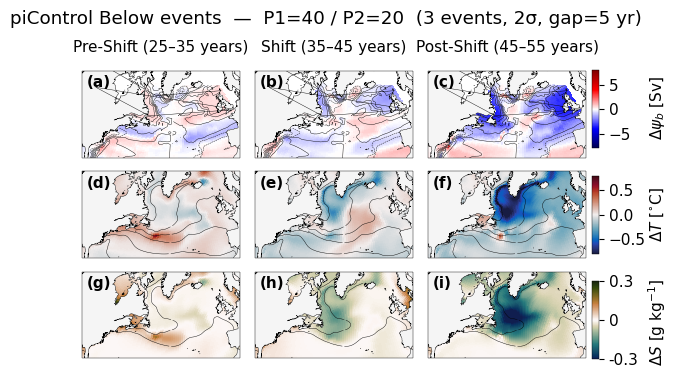

In [8]:
import os

P1_40, P2_40 = 40, 20
tag_40 = f'2.0_{P1_40}_{P2_40}_picontrol'

da_bsf_40    = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_bsf_{tag_40}.nc'))['BSF']
da_thetao_40 = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_thetao_{tag_40}.nc'))['thetao']
da_so_40     = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_so_{tag_40}.nc'))['so']

print(f'BSF    dims: {da_bsf_40.dims}, shape: {da_bsf_40.shape}')
print(f'thetao dims: {da_thetao_40.dims}, shape: {da_thetao_40.shape}')
print(f'so     dims: {da_so_40.dims}, shape: {da_so_40.shape}')

plot_flipbook_inline(da_bsf_40, da_thetao_40, da_so_40, P1_40, P2_40, n_events=3)

### Config P1 = 20 / P2 = 20  (13 Below events)

Baseline window = 20 yr  ·  Test window = 20 yr  ·  Composite column slices: (5–15), (15–25), (25–35) years.
Many more events than the P1=40 config — compare the amplitude and spatial pattern.

BSF    dims: ('time', 'nlat', 'nlon'), shape: (40, 384, 320)
thetao dims: ('time', 'lev', 'nlat', 'nlon'), shape: (40, 60, 384, 320)
so     dims: ('time', 'lev', 'nlat', 'nlon'), shape: (40, 60, 384, 320)


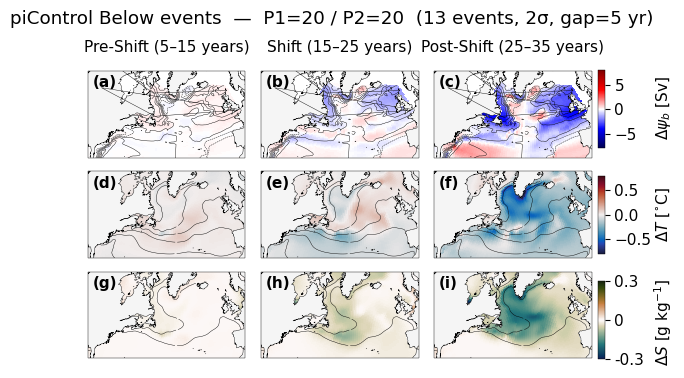

In [9]:
P1_20, P2_20 = 20, 20
tag_20 = f'2.0_{P1_20}_{P2_20}_picontrol'

da_bsf_20    = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_bsf_{tag_20}.nc'))['BSF']
da_thetao_20 = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_thetao_{tag_20}.nc'))['thetao']
da_so_20     = xr.open_dataset(os.path.join(OUTPUT_DIR, f'Below_combined_so_{tag_20}.nc'))['so']

print(f'BSF    dims: {da_bsf_20.dims}, shape: {da_bsf_20.shape}')
print(f'thetao dims: {da_thetao_20.dims}, shape: {da_thetao_20.shape}')
print(f'so     dims: {da_so_20.dims}, shape: {da_so_20.shape}')

plot_flipbook_inline(da_bsf_20, da_thetao_20, da_so_20, P1_20, P2_20, n_events=13)